# **SelfCheckGPT on RAGTruth**

In [ ]:
# Restart after running this cell.
!pip install -q "transformers==4.36.2" selfcheckgpt sentencepiece "accelerate>=0.26,<1.0" "bitsandbytes>=0.43.0"
!python -m spacy download en_core_web_sm -q

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
sentence-transformers 5.7.0 requires tokenizers>=0.19, but you have tokenizers 0.15.2 which is incompatible.
sentence-transformers 5.7.0 requires transformers<6.0.0,>=4.41.0, but you have transformers 4.36.2 which is incompatible.
gradio 6.30.0 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
gradio-client 2.7.2 requires huggingface-hub<3.0,>=1.16.0, but you have huggingface-hub 0.36.2 which is incompatible.
diffusers 0.41.0 requires huggingface-hub<2.0,>=1.32.0, but you have huggingface-hub 0.36.2 which is incompatible.
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_sm')
⚠ Restart to 

In [ ]:
import os, gc, time, pickle, json, functools, urllib.request, warnings
from collections import Counter
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from sklearn.metrics import precision_recall_curve, auc, roc_auc_score
import spacy

warnings.filterwarnings("ignore", category=FutureWarning)
if not hasattr(spacy.load, "cache_info"):
    spacy.load = functools.lru_cache(maxsize=None)(spacy.load)
nlp = spacy.load("en_core_web_sm")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 2**30 if device.type == "cuda" else 0.0
print(f"Using device: {device}" + (f" - {torch.cuda.get_device_name(0)} ({GPU_GB:.1f} GB)" if device.type == "cuda" else "  (WARNING: no GPU)"))

try:
    from google.colab import drive
    drive.mount('/content/drive')
    RESULTS_DIR = "/content/drive/MyDrive/ExistingDatasets"
except ImportError:
    RESULTS_DIR = "./selfcheckgpt_results"
os.makedirs(RESULTS_DIR, exist_ok=True)
print("Results / caches ->", RESULTS_DIR)
WIKIBIO_DIRS = [RESULTS_DIR, os.path.join(os.path.dirname(RESULTS_DIR), "selfcheckgpt_replication_results")]

Using device: cuda - Tesla T4 (14.6 GB)
Mounted at /content/drive
Results / caches -> /content/drive/MyDrive/ExistingDatasets


### Configuration

In [ ]:
SEED = 42

# SelfCheckGPT variants (MQAG is omitted: far too slow for long RAG responses)
RUN_UNIGRAM   = True
RUN_BERTSCORE = True
RUN_NLI       = True
RUN_PROMPT    = True

# Sampling
N_SAMPLES    = 5
SAMPLER_LLM  = "mistralai/Mistral-7B-Instruct-v0.2"
SAMPLER_TEMP = 1.0
GEN_BATCH    = 5
HF_4BIT      = "auto"
PROMPT_BATCH = 20

# RAGTruth
RAG_MODELS      = ["mistral-7B-instruct"]
RAG_N_PER_TASK  = 10
RAG_GOOD_QUALITY_ONLY = True
RAG_MAX_PROMPT_TOKENS = 1500
RAG_MAX_NEW_TOKENS    = 200

N_BOOT = 500
np.random.seed(SEED); torch.manual_seed(SEED)

In [ ]:
# ---------- utilities: resumable caching, GPU clean-up ----------
def cache_path(name): return os.path.join(RESULTS_DIR, f"cache_{name}.pkl")
def load_cache(name):
    p = cache_path(name)
    if os.path.exists(p):
        with open(p, "rb") as f: return pickle.load(f)
    return {}
def save_cache(name, obj):
    p = cache_path(name); tmp = p + ".tmp"
    with open(tmp, "wb") as f: pickle.dump(obj, f)
    os.replace(tmp, p)
def run_cached(name, fn, keys, desc, save_every=10):
    cache = load_cache(name)
    todo = [k for k in keys if k not in cache]
    print(f"{desc}: {len(keys) - len(todo)} cached, {len(todo)} to compute")
    for n, k in enumerate(tqdm(todo, desc=desc)):
        cache[k] = fn(k)
        if (n + 1) % save_every == 0: save_cache(name, cache)
    if todo: save_cache(name, cache)
    return {k: cache[k] for k in keys}
def free(*names):
    for n in names: globals().pop(n, None)
    gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
def fetch_jsonl(url, fname):
    # download once into RESULTS_DIR, then read from there
    p = os.path.join(RESULTS_DIR, fname)
    if not os.path.exists(p):
        print("downloading", url); urllib.request.urlretrieve(url, p)
    with open(p, encoding="utf-8") as f: return [json.loads(l) for l in f if l.strip()]
def ram(tag=""):
    # print this process' RAM and the machine's RAM (to see how close to the Colab limit)
    import psutil
    vm = psutil.virtual_memory(); me = psutil.Process().memory_info().rss / 2**30
    print(f"[RAM {tag}] this process {me:.1f} GB | system used {vm.used / 2**30:.1f} / {vm.total / 2**30:.1f} GB")

### Models

In [ ]:
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig
llm_tok = AutoTokenizer.from_pretrained(SAMPLER_LLM, use_fast=False)  
llm_tok.padding_side = "left"
if llm_tok.pad_token is None: llm_tok.pad_token = llm_tok.eos_token
LLM = {}
OOM = getattr(torch.cuda, "OutOfMemoryError", RuntimeError)

def get_llm():
    if "model" not in LLM:
        use_4bit = (GPU_GB < 20) if HF_4BIT == "auto" else bool(HF_4BIT)
        if use_4bit:
            LLM["model"] = AutoModelForCausalLM.from_pretrained(SAMPLER_LLM, device_map={"": 0}, low_cpu_mem_usage=True,
                quantization_config=BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_compute_dtype=torch.float16))
        else:
            LLM["model"] = AutoModelForCausalLM.from_pretrained(SAMPLER_LLM, torch_dtype=torch.float16, device_map={"": 0}, low_cpu_mem_usage=True)
        LLM["model"].eval()
        print(f"{SAMPLER_LLM} loaded ({'4-bit NF4' if use_4bit else 'fp16'})")
    return LLM["model"]

def chat_ids(prompt):
    return llm_tok.apply_chat_template([{"role": "user", "content": prompt}], tokenize=True, add_generation_prompt=True, return_tensors="pt")

@torch.no_grad()
def sample_responses(prompt, n, max_new_tokens, temperature=None):
    # n stochastic responses to `prompt`: pure sampling (no top-k / top-p), as in SelfCheckGPT
    temperature = SAMPLER_TEMP if temperature is None else temperature
    model = get_llm()
    ids = chat_ids(prompt).to(device)
    outs, todo, cur = [], n, GEN_BATCH
    while todo > 0:
        k = min(cur, todo)
        try:
            g = model.generate(ids, attention_mask=torch.ones_like(ids), do_sample=True, temperature=temperature, top_p=1.0, top_k=0,
                               max_new_tokens=max_new_tokens, num_return_sequences=k, pad_token_id=llm_tok.pad_token_id)
        except OOM:
            torch.cuda.empty_cache()
            if cur == 1: raise
            cur = max(1, cur // 2); print(f"OOM -> generation batch {cur}"); continue
        outs += llm_tok.batch_decode(g[:, ids.shape[1]:], skip_special_tokens=True)
        todo -= k
    return [o.strip() for o in outs]

if RUN_NLI:
    from selfcheckgpt.modeling_selfcheck import SelfCheckNLI
    selfcheck_nli = SelfCheckNLI(device=device)
    nli_tok, nli_model = selfcheck_nli.tokenizer, selfcheck_nli.model
if RUN_BERTSCORE:
    from bert_score import BERTScorer
    from selfcheckgpt.utils import expand_list1, expand_list2
    bs_scorer = BERTScorer(lang="en", rescale_with_baseline=True, device=str(device))
ram("after loading scorers")

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.model:   0%|          | 0.00/493k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/414 [00:00<?, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

tokenizer_config.json:   0%|          | 0.00/400 [00:00<?, ?B/s]

... (9 outputs left out)

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

[RAM after loading scorers] this process 3.4 GB | system used 4.4 / 12.7 GB


### SelfCheckGPT scorers

In [ ]:
@torch.no_grad()
def nli_matrix(sentences, samples, batch_size=20):
    M = np.zeros((len(sentences), len(samples)))
    for si, sentence in enumerate(sentences):
        for b in range(0, len(samples), batch_size):
            chunk = samples[b:b + batch_size]
            inputs = nli_tok([sentence] * len(chunk), chunk, add_special_tokens=True, padding="longest", truncation=True,
                             return_tensors="pt", return_token_type_ids=True, return_attention_mask=True).to(device)
            probs = torch.softmax(nli_model(**inputs).logits, dim=-1)
            M[si, b:b + len(chunk)] = probs[:, 1].cpu().numpy()          # P(contradiction)
    return M

def bertscore_matrix(sentences, samples, split_samples=True):
    # split_samples=False treats every sample as one unit (short QA statements must not be sentence-split)
    M = np.zeros((len(sentences), len(samples)))
    for s_i, sample in enumerate(samples):
        sent_sample = ([x.text.strip() for x in nlp(sample).sents if len(x) > 3] if split_samples else ([sample] if sample.strip() else []))
        if not sent_sample: continue
        refs, cands = expand_list1(sentences, len(sent_sample)), expand_list2(sent_sample, len(sentences))
        _, _, F1 = bs_scorer.score(cands, refs)
        M[:, s_i] = F1.reshape(len(sentences), len(sent_sample)).max(dim=1).values.numpy()
    return M

@functools.lru_cache(maxsize=None)
def _sent_tokens(text):  return tuple(tuple(t.text for t in nlp(s.text.strip())) for s in nlp(text).sents)
@functools.lru_cache(maxsize=None)
def _tokens(sentence):   return tuple(t.text for t in nlp(sentence))

def fast_unigram(sentences, passage, samples):
    # SelfCheck-Unigram: unigram LM on the response + samples; sentence score = max token negative log-prob 
    from collections import Counter as C
    counts, total = C(), 0
    for text in [passage] + list(samples):
        for toks in _sent_tokens(text):
            toks = [t.lower() for t in toks]; counts.update(toks); total += len(toks)
    out = []
    with np.errstate(divide="ignore"):
        for sent in sentences:
            lp = [np.log(counts.get(t.lower(), 0) / total) for t in _tokens(sent)]
            out.append(-np.min(lp) if lp else 0.0)
    return np.array(out)

PROMPT_TEMPLATE = "Context: {context}\n\nSentence: {sentence}\n\nIs the sentence supported by the context above? Answer Yes or No.\n\nAnswer: "
NA_OUTPUTS = Counter()
def map_answer(text):
    t = text.lower().strip()
    if t[:3] == "yes": return 0.0
    if t[:2] == "no":  return 1.0
    NA_OUTPUTS[t] += 1
    return 0.5

@torch.no_grad()
def prompt_matrix(sentences, samples):
    model = get_llm()
    M = np.zeros((len(sentences), len(samples)))
    for si, sentence in enumerate(sentences):
        prompts = [PROMPT_TEMPLATE.format(context=s.replace("\n", " "), sentence=sentence.replace("\n", " ")) for s in samples]
        for b in range(0, len(prompts), PROMPT_BATCH):
            chunk = prompts[b:b + PROMPT_BATCH]
            enc = llm_tok(chunk, return_tensors="pt", padding=True).to(device)
            out = model.generate(**enc, max_new_tokens=5, do_sample=False, pad_token_id=llm_tok.pad_token_id)
            texts = llm_tok.batch_decode(out[:, enc["input_ids"].shape[1]:], skip_special_tokens=True, clean_up_tokenization_spaces=False)
            for k, t in enumerate(texts): M[si, b + k] = map_answer(t)
    return M

### Evaluation utilities

In [6]:
def metrics_binary(y, s):
    y = np.asarray(y).astype(int); s = np.asarray(s, float)
    if not np.isfinite(s).all(): raise ValueError("non-finite scores")
    if y.sum() == 0 or y.sum() == len(y): return {"AUC_PR": np.nan, "AUROC": np.nan, "prevalence": 100 * y.mean()}
    P, R, _ = precision_recall_curve(y, s)
    return {"AUC_PR": 100 * auc(R, P), "AUROC": 100 * roc_auc_score(y, s), "prevalence": 100 * y.mean()}

def _units(items, scores, level):
    per = []
    for it in items:
        sc = np.asarray(scores[it["id"]], float)
        if level == "sentence":        per.append((np.asarray(it["labels"]), sc))
        elif level == "response_mean": per.append((np.array([it["resp_label"]]), np.array([sc.mean()])))
        elif level == "response_max":  per.append((np.array([it["resp_label"]]), np.array([sc.max()])))
    return per

def evaluate_items(items, scores, level="sentence", group=None, n_boot=None):
    n_boot = N_BOOT if n_boot is None else n_boot
    sel = [it for it in items if it["id"] in scores and (group in (None, "ALL") or it["group"] == group)]
    per = _units(sel, scores, level)
    if not per: return None
    y = np.concatenate([p[0] for p in per]); s = np.concatenate([p[1] for p in per])
    m = metrics_binary(y, s)
    res = {"n_items": len(sel), "n_units": len(y), **m}
    rng = np.random.default_rng(SEED); boots = {"AUC_PR": [], "AUROC": []}
    if n_boot and not np.isnan(m["AUROC"]):
        for _ in range(n_boot):
            idx = rng.integers(0, len(per), len(per))
            mb = metrics_binary(np.concatenate([per[i][0] for i in idx]), np.concatenate([per[i][1] for i in idx]))
            for k in boots:
                if not np.isnan(mb[k]): boots[k].append(mb[k])
    for k in ("AUC_PR", "AUROC"):
        res[k + "_lo"], res[k + "_hi"] = ((np.percentile(boots[k], 2.5), np.percentile(boots[k], 97.5)) if len(boots[k]) > 0.5 * max(n_boot, 1) and n_boot else (np.nan, np.nan))
    return res

def fmt(r, k):
    if r is None or np.isnan(r[k]): return "-"
    lo, hi = r.get(k + "_lo", np.nan), r.get(k + "_hi", np.nan)
    return f"{r[k]:.1f}" + (f" [{lo:.0f}-{hi:.0f}]" if not np.isnan(lo) else "")

def results_table(items, SC, groups, levels, dataset):
    rows = []
    for level in levels:
        for method, scores in SC.items():
            for g in ["ALL"] + groups:
                r = evaluate_items(items, scores, level, g)
                if r: rows.append({"dataset": dataset, "level": level, "method": method, "group": g, **r})
    return pd.DataFrame(rows)

def show_pivot(df, level, metric):
    sub = df[df.level == level]
    if sub.empty: return
    t = sub.assign(cell=sub.apply(lambda r: fmt(r, metric), axis=1)).pivot(index="method", columns="group", values="cell")
    prev = sub.drop_duplicates("group").set_index("group")["prevalence"]
    nitems = sub.drop_duplicates("group").set_index("group")["n_items"]
    t.loc["(positive rate %)"] = prev.map(lambda x: f"{x:.1f}")
    t.loc["(# items)"] = nitems.map(str)
    cols = ["ALL"] + [c for c in t.columns if c != "ALL"]
    print(f"{level}-level {metric}  (95% cluster-bootstrap CI)"); display(t[cols])

# **RAGTruth**

In [7]:
RAG_URL = "https://raw.githubusercontent.com/ParticleMedia/RAGTruth/main/dataset/"
rag_resp = fetch_jsonl(RAG_URL + "response.jsonl", "ragtruth_response.jsonl")
rag_src  = {s["source_id"]: s for s in fetch_jsonl(RAG_URL + "source_info.jsonl", "ragtruth_source_info.jsonl")}
df = pd.DataFrame([{"model": r["model"], "split": r["split"], "task": rag_src[r["source_id"]]["task_type"], "quality": r["quality"],
                    "hallucinated": any(not l.get("implicit_true") for l in r["labels"])} for r in rag_resp])
print(f"{len(rag_resp)} responses, {len(rag_src)} prompts")
display(df[df.split == "test"].groupby(["model", "task"]).agg(n=("task", "size"), hallucinated_rate=("hallucinated", "mean")).round(2).unstack("task"))

17790 responses, 2965 prompts


n              hallucinated_rate              
task                Data2txt   QA Summary          Data2txt    QA Summary
model                                                                    
gpt-3.5-turbo-0613       150  150     150              0.23  0.02    0.03
gpt-4-0613               150  150     150              0.22  0.01    0.04
llama-2-13b-chat         150  150     150              0.91  0.19    0.21
llama-2-70b-chat         150  150     150              0.73  0.19    0.16
llama-2-7b-chat          150  150     150              0.79  0.32    0.32
mistral-7B-instruct      150  150     150              0.88  0.17    0.55

### Spans -> sentence labels

In [8]:
def build_rag_items():
    rng = np.random.default_rng(SEED)
    pool = []
    for r in rag_resp:
        if r["split"] != "test" or r["model"] not in RAG_MODELS: continue
        if RAG_GOOD_QUALITY_ONLY and r["quality"] != "good": continue
        s = rag_src[r["source_id"]]
        if len(chat_ids(s["prompt"])[0]) > RAG_MAX_PROMPT_TOKENS: continue
        doc = nlp(r["response"])
        sents = [(x.start_char, x.end_char, x.text.strip()) for x in doc.sents if x.text.strip()]
        if not sents: continue
        spans = [(l["start"], l["end"]) for l in r["labels"] if not l.get("implicit_true")]
        labels = np.array([int(any(a < e and b > st for a, b in spans)) for st, e, _ in sents])
        pool.append({"id": f"rag_{r['id']}", "group": s["task_type"], "generator": r["model"], "prompt": s["prompt"], "text": r["response"],
                     "sentences": [t for _, _, t in sents], "labels": labels, "resp_label": int(labels.any()), "n_spans": len(spans)})
    items = []
    for task in sorted({it["group"] for it in pool}):
        for gen in RAG_MODELS:
            sub = [it for it in pool if it["group"] == task and it["generator"] == gen]
            pick = rng.permutation(len(sub))[:RAG_N_PER_TASK]
            items += [sub[i] for i in sorted(pick)]
    return items

rag_items = build_rag_items()
st = pd.DataFrame([{"task": it["group"], "n_sent": len(it["labels"]), "n_hall_sent": int(it["labels"].sum()), "resp_halluc": it["resp_label"]} for it in rag_items])
print(f"{len(rag_items)} RAGTruth items selected (generators: {RAG_MODELS})")
display(st.groupby("task").agg(responses=("task", "size"), sentences=("n_sent", "sum"), hallucinated_sentences=("n_hall_sent", "sum"),
                              responses_with_hallucination=("resp_halluc", "sum")))
k = next(it for it in rag_items if it["resp_label"])
print("\nExample (task:", k["group"], ")")
for t, l in list(zip(k["sentences"], k["labels"]))[:6]: print(f"  [{'HALLUCINATED' if l else 'ok          '}] {t[:110]}")

30 RAGTruth items selected (generators: ['mistral-7B-instruct'])


,responses,sentences,hallucinated_sentences,responses_with_hallucination
task,,,,
Data2txt,10,78,15,10
QA,10,46,3,3
Summary,10,57,6,6



Example (task: Data2txt )
  [ok          ] Pizza Mizza is a food delivery services and restaurant located in Santa Barbara, CA.
  [ok          ] They offer a variety of pizzas, Italian dishes, salads, and sandwiches.
  [ok          ] Customers can choose from regular or gluten-free crusts and cauliflower options.
  [ok          ] Pizza Mizza has outdoor seating and offers takeout.
  [ok          ] They also have WiFi available.
  [HALLUCINATED] The business has a 3.5 star rating on Google.


### Re-sampling from the original prompt

In [9]:
t0 = time.time()
by_id = {it["id"]: it for it in rag_items}
rag_samples = run_cached("ext_rag_samples", lambda i: sample_responses(by_id[i]["prompt"], N_SAMPLES, RAG_MAX_NEW_TOKENS),
                         [it["id"] for it in rag_items], "RAGTruth sampling", save_every=3)
for it in rag_items: it["samples"] = rag_samples[it["id"]]
print(f"done in {(time.time() - t0) / 60:.1f} min")
lens = [len(s.split()) for it in rag_items for s in it["samples"]]
print(f"sample length: mean {np.mean(lens):.0f} words;  empty samples: {sum(l == 0 for l in lens)};  original responses: {np.mean([len(it['text'].split()) for it in rag_items]):.0f} words")
print("\nOriginal response (first 300 chars):", rag_items[0]["text"][:300]); print("Sample 1:", rag_items[0]["samples"][0][:300])

RAGTruth sampling: 1 cached, 29 to compute


RAGTruth sampling:   0%|          | 0/29 [00:00<?, ?it/s]

config.json:   0%|          | 0.00/596 [00:00<?, ?B/s]

model.safetensors.index.json: 0.00B [00:00, ?B/s]

model-00001-of-00003.safetensors:   0%|          | 0.00/4.94G [00:00<?, ?B/s]

model-00002-of-00003.safetensors:   0%|          | 0.00/5.00G [00:00<?, ?B/s]

model-00003-of-00003.safetensors:   0%|          | 0.00/4.54G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/3 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/111 [00:00<?, ?B/s]

mistralai/Mistral-7B-Instruct-v0.2 loaded (4-bit NF4)
done in 24.8 min
sample length: mean 125 words;  empty samples: 0;  original responses: 109 words

Original response (first 300 chars): Pizza Mizza is a food delivery services and restaurant located in Santa Barbara, CA. They offer a variety of pizzas, Italian dishes, salads, and sandwiches. Customers can choose from regular or gluten-free crusts and cauliflower options. Pizza Mizza has outdoor seating and offers takeout. They also 
Sample 1: Pizza Mizza, located in Santa Barbara, CA, is a food delivery and Italian restaurant specializing in pizzas. The business is open from 11:00 AM to 9:00 PM every day and offers various amenities such as takeout, outdoor seating, free Wi-Fi, and reservations. According to the structured data, Pizza Mi


### Score with SelfCheckGPT

In [10]:
def run_scoring(tag, items, split_samples=True):
    ids = [it["id"] for it in items]; by_id = {it["id"]: it for it in items}
    SC, MT = {}, {}
    if RUN_UNIGRAM:
        sc = {i: fast_unigram(by_id[i]["sentences"], by_id[i]["text"], by_id[i]["samples"]) for i in ids}
        allv = np.concatenate(list(sc.values())); cap = allv[np.isfinite(allv)].max()
        n_bad = int((~np.isfinite(allv)).sum())
        if n_bad: print(f"unigram: {n_bad} non-finite sentence scores capped at {cap:.2f}")
        SC["Unigram (max)"] = {i: np.where(np.isfinite(v), v, cap) for i, v in sc.items()}
    if RUN_BERTSCORE:
        MT["BERTScore"] = run_cached(f"ext_{tag}_bertscore", lambda i: bertscore_matrix(by_id[i]["sentences"], by_id[i]["samples"], split_samples), ids, "BERTScore", 10)
        SC["BERTScore"] = {i: 1.0 - M.mean(axis=1) for i, M in MT["BERTScore"].items()}
    if RUN_NLI:
        MT["NLI"] = run_cached(f"ext_{tag}_nli", lambda i: nli_matrix(by_id[i]["sentences"], by_id[i]["samples"]), ids, "NLI", 10)
        SC["NLI"] = {i: M.mean(axis=1) for i, M in MT["NLI"].items()}
    if RUN_PROMPT:
        MT["Prompt"] = run_cached(f"ext_{tag}_prompt_{SAMPLER_LLM.split('/')[-1]}", lambda i: prompt_matrix(by_id[i]["sentences"], by_id[i]["samples"]), ids, "Prompt", 5)
        SC["Prompt"] = {i: M.mean(axis=1) for i, M in MT["Prompt"].items()}
        print(f"non Yes/No outputs (scored 0.5): {sum(NA_OUTPUTS.values())} {dict(NA_OUTPUTS.most_common(3))}")
    return SC, MT

t0 = time.time()
RAG_SC, RAG_MT = run_scoring("rag", rag_items)
print(f"done in {(time.time() - t0) / 60:.1f} min")

BERTScore: 0 cached, 30 to compute


BERTScore:   0%|          | 0/30 [00:00<?, ?it/s]

NLI: 0 cached, 30 to compute


NLI:   0%|          | 0/30 [00:00<?, ?it/s]

Prompt: 0 cached, 30 to compute


Prompt:   0%|          | 0/30 [00:00<?, ?it/s]

non Yes/No outputs (scored 0.5): 17 {'the sentence is': 8, 'partially.': 3, 'the context above': 3}
done in 7.1 min


### RAGTruth results

In [11]:
RAG_TASKS = sorted({it["group"] for it in rag_items})
RAG_RES = results_table(rag_items, RAG_SC, RAG_TASKS, ["sentence", "response_mean", "response_max"], "RAGTruth")
for level in ("sentence", "response_mean"):
    for metric in ("AUC_PR", "AUROC"):
        show_pivot(RAG_RES, level, metric); print()
RAG_RES.to_csv(os.path.join(RESULTS_DIR, "ext_ragtruth_results.csv"), index=False)

sentence-level AUC_PR  (95% cluster-bootstrap CI)


group,ALL,Data2txt,QA,Summary
method,,,,
BERTScore,20.9 [13-35],52.2 [31-71],6.0 [1-15],13.2 [4-29]
NLI,34.5 [19-49],44.4 [23-69],42.0 [2-100],17.8 [5-60]
Prompt,42.7 [25-63],67.4 [44-86],43.7 [1-100],14.8 [2-69]
Unigram (max),12.9 [9-22],16.2 [10-35],24.3 [2-57],7.7 [3-31]
(positive rate %),13.3,19.2,6.5,10.5
(# items),30,10,10,10



sentence-level AUROC  (95% cluster-bootstrap CI)


group,ALL,Data2txt,QA,Summary
method,,,,
BERTScore,60.8 [45-74],72.9 [58-86],35.7 [0-90],50.7 [20-81]
NLI,70.0 [57-81],70.3 [52-85],74.4 [39-100],68.0 [47-87]
Prompt,68.9 [57-81],74.1 [59-90],78.7 [46-100],54.2 [43-73]
Unigram (max),52.3 [41-63],45.8 [30-59],62.0 [30-93],38.4 [23-57]
(positive rate %),13.3,19.2,6.5,10.5
(# items),30,10,10,10



response_mean-level AUC_PR  (95% cluster-bootstrap CI)


group,ALL,Data2txt,QA,Summary
method,,,,
BERTScore,67.9 [46-91],-,27.4 [6-93],78.5 [37-100]
NLI,62.9 [43-91],-,34.9 [8-100],59.2 [19-100]
Prompt,74.1 [53-93],-,80.0 [5-100],41.7 [15-94]
Unigram (max),71.5 [48-96],-,34.2 [8-100],48.7 [19-91]
(positive rate %),63.3,100.0,30.0,60.0
(# items),30,10,10,10



response_mean-level AUROC  (95% cluster-bootstrap CI)


group,ALL,Data2txt,QA,Summary
method,,,,
BERTScore,58.9 [36-83],-,52.4 [12-92],58.3 [15-100]
NLI,57.4 [30-84],-,66.7 [25-100],37.5 [0-100]
Prompt,59.3 [38-78],-,78.6 [31-100],29.2 [0-64]
Unigram (max),68.9 [49-92],-,66.7 [29-100],33.3 [0-76]
(positive rate %),63.3,100.0,30.0,60.0
(# items),30,10,10,10


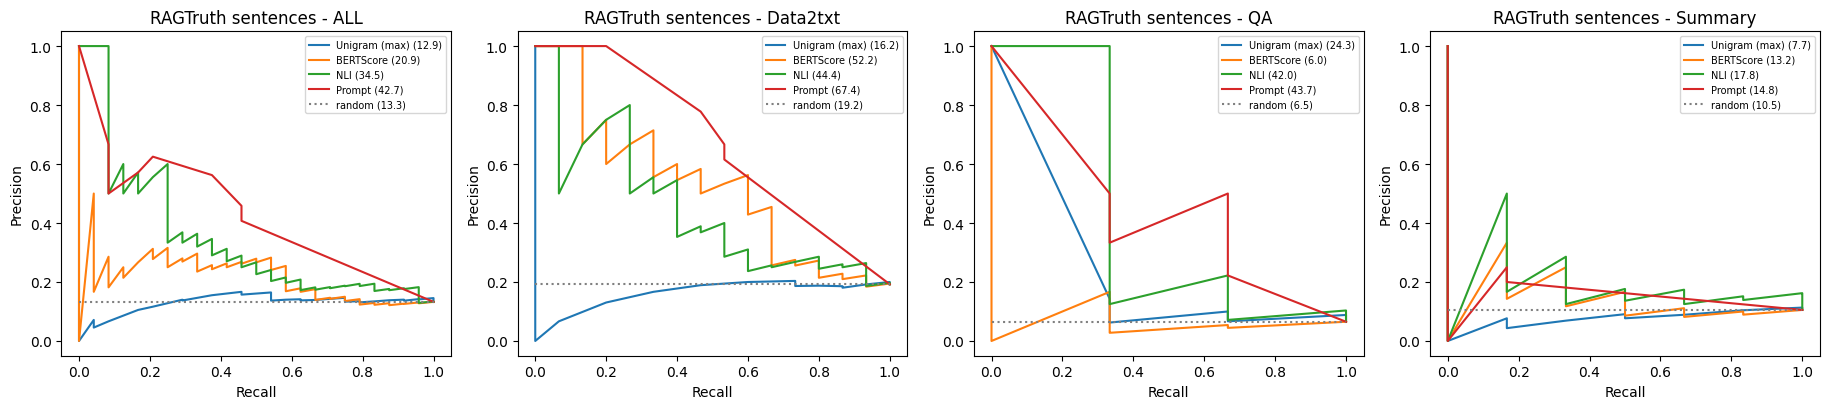

In [12]:
fig, axes = plt.subplots(1, 1 + len(RAG_TASKS), figsize=(4.6 * (1 + len(RAG_TASKS)), 4.2))
for ax, g in zip(axes, ["ALL"] + RAG_TASKS):
    sel = [it for it in rag_items if g == "ALL" or it["group"] == g]
    y = np.concatenate([it["labels"] for it in sel])
    for method, sc in RAG_SC.items():
        s = np.concatenate([sc[it["id"]] for it in sel])
        if y.sum() == 0: continue
        P, R, _ = precision_recall_curve(y, s); ax.plot(R, P, label=f"{method} ({100 * auc(R, P):.1f})")
    ax.hlines(y.mean(), 0, 1, colors="grey", linestyles="dotted", label=f"random ({100 * y.mean():.1f})")
    ax.set_title(f"RAGTruth sentences - {g}"); ax.set_xlabel("Recall"); ax.set_ylabel("Precision"); ax.legend(fontsize=7)
plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "ext_ragtruth_pr_curves.png"), dpi=150); plt.show()

# **Effect of the number of samples**

Recomputed from the cached matrices (first *N* of the samples), as in the paper's Fig. 7/8. Unigram is omitted (it needs re-fitting per N).

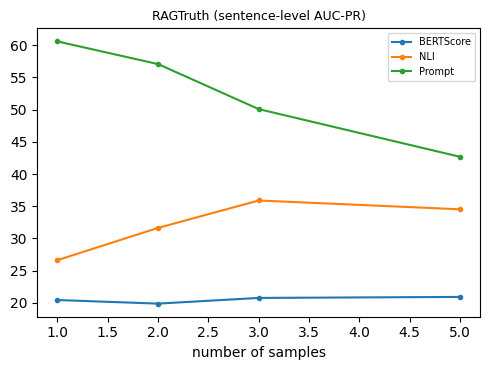

In [13]:
def ablate(items, MT, metric, level="sentence"):
    Ns = [n for n in (1, 2, 3, 5, 7, 10, 15, 20) if n <= N_SAMPLES]
    curves = {}
    for method, mats in MT.items():
        vals = []
        for n in Ns:
            sc = {i: ((1.0 - M[:, :n].mean(axis=1)) if method == "BERTScore" else M[:, :n].mean(axis=1)) for i, M in mats.items()}
            r = evaluate_items(items, sc, level, None, n_boot=0); vals.append(r[metric])
        curves[method] = vals
    return Ns, curves

if RAG_MT:
    Ns, curves = ablate(rag_items, RAG_MT, "AUC_PR")
    fig, ax = plt.subplots(figsize=(5, 3.8))
    for m, v in curves.items(): ax.plot(Ns, v, marker="o", ms=3, label=m)
    ax.set_title("RAGTruth (sentence-level AUC-PR)", fontsize=9); ax.set_xlabel("number of samples"); ax.legend(fontsize=7)
    plt.tight_layout(); plt.savefig(os.path.join(RESULTS_DIR, "ext_ragtruth_num_samples.png"), dpi=150); plt.show()

# **Comparison with the WikiBio replication**

In [14]:
rows = []
def add(dataset, df, level="sentence", group="ALL"):
    for _, r in df[(df.level == level) & (df.group == group)].iterrows():
        rows.append({"dataset": dataset, "method": r["method"], "AUC-PR": r["AUC_PR"], "random (positive rate)": r["prevalence"],
                     "lift": r["AUC_PR"] - r["prevalence"], "AUROC": r["AUROC"], "n_items": r["n_items"]})
add("RAGTruth - sentences (Mistral-7B responses)", RAG_RES)

sp = next((p for p in (os.path.join(d, "summary.json") for d in WIKIBIO_DIRS) if os.path.exists(p)), None)
if sp:
    print("WikiBio numbers read from", sp)
    t2 = json.load(open(sp)).get("table2", {})
    for name, m in t2.items():
        if m.get("NonFact") is not None:
            short = {"SelfCheck-Unigram (max)": "Unigram (max)", "SelfCheck-BERTScore": "BERTScore", "SelfCheck-NLI": "NLI"}.get(name, "Prompt" if "Prompt" in name else None)
            if short: rows.append({"dataset": "WikiBio - sentences (GPT-3), NonFact", "method": short, "AUC-PR": m["NonFact"], "random (positive rate)": 72.96,
                                   "lift": m["NonFact"] - 72.96, "AUROC": np.nan, "n_items": m.get("n_passages")})
else:
    print("summary.json from the replication notebook not found in", WIKIBIO_DIRS, "- WikiBio rows omitted")
SUMMARY = pd.DataFrame(rows).sort_values(["dataset", "method"])
display(SUMMARY.round(1).style.hide(axis="index"))
SUMMARY.to_csv(os.path.join(RESULTS_DIR, "ext_summary_ragtruth_vs_wikibio.csv"), index=False)

summary.json from the replication notebook not found in ['/content/drive/MyDrive/ExistingDatasets', '/content/drive/MyDrive/selfcheckgpt_replication_results'] - WikiBio rows omitted


dataset,method,AUC-PR,random (positive rate),lift,AUROC,n_items
RAGTruth - sentences (Mistral-7B responses),BERTScore,20.900000,13.300000,7.700000,60.800000,30
RAGTruth - sentences (Mistral-7B responses),NLI,34.500000,13.300000,21.300000,70.000000,30
RAGTruth - sentences (Mistral-7B responses),Prompt,42.700000,13.300000,29.400000,68.900000,30
RAGTruth - sentences (Mistral-7B responses),Unigram (max),12.900000,13.300000,-0.400000,52.300000,30
